In [1]:

import pandas as pd
import plotly.graph_objects as go


In [2]:
import os

print("Current folder:", os.getcwd())
print("Files in this folder:", os.listdir())

Current folder: C:\Users\Sunny\DV_Exercises
Files in this folder: ['.ipynb_checkpoints', 'co2_emissions.csv', 'lecture03_exercise.ipynb']


In [3]:
import pandas as pd
import plotly.graph_objects as go

df = pd.read_csv('co2_emissions.csv')

print("Rows:", len(df))
print("Countries:", df['Country'].nunique())
print("Years:", df['Year'].min(), "-", df['Year'].max())

df.head()


Rows: 345
Countries: 15
Years: 2000 - 2022


,Country,Region,Year,CO2_Mt,CO2_per_capita
0,United States,North America,2000,5857.6,1.32
1,United States,North America,2001,5724.0,1.26
2,United States,North America,2002,5652.8,1.11
3,United States,North America,2003,5592.8,1.29
4,United States,North America,2004,5743.2,1.12


In [4]:
print("Countries:")
print(df['Country'].unique())

print("\nRegions:")
print(df['Region'].unique())

print("\nCO2 emissions range:")
print(df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")

print("\nRegional averages in 2022:")
print(
    df[df['Year'] == 2022]
    .groupby('Region')['CO2_Mt']
    .mean()
    .sort_values(ascending=False)
    .round(1)
)


Countries:
<ArrowStringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

Regions:
<ArrowStringArray>
['North America', 'Asia', 'Europe', 'Latin America', 'Oceania', 'Africa']
Length: 6, dtype: str

CO2 emissions range:
125.3 to 12409.5 Mt

Regional averages in 2022:
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


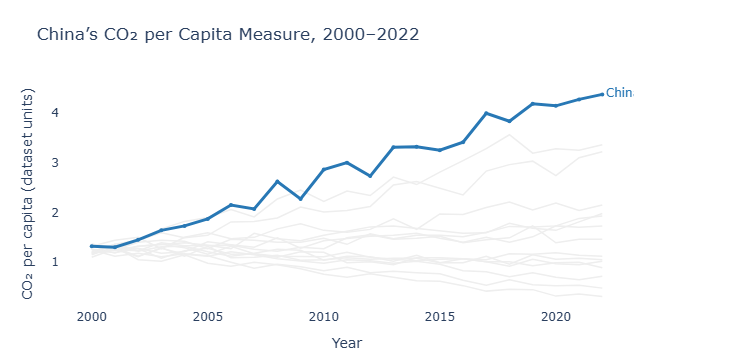

In [5]:
highlight_country = 'China'
fig = go.Figure()

# Draw all countries in light grey
for country in df['Country'].unique():
    country_df = df[df['Country'] == country].sort_values('Year')

    fig.add_trace(go.Scatter(
        x=country_df['Year'],
        y=country_df['CO2_per_capita'],
        mode='lines',
        line=dict(color='#EEEEEE', width=1.5),
        hovertemplate=(
            f'{country}<br>Year: %{{x}}'
            '<br>CO2 per capita: %{y:.2f}<extra></extra>'
        ),
        showlegend=False
    ))

china_df = (
    df[df['Country'] == highlight_country]
    .sort_values('Year')
)

labels = [''] * len(china_df)
labels[-1] = 'China'

fig.add_trace(go.Scatter(
    x=china_df['Year'],
    y=china_df['CO2_per_capita'],
    mode='lines+markers+text',
    line=dict(color='#2878B5', width=3),
    marker=dict(size=4),
    text=labels,
    textposition='middle right',
    textfont=dict(color='#2878B5', size=12),
    showlegend=False
))

fig.update_layout(
    title='China’s CO₂ per Capita Measure, 2000–2022',
    xaxis_title='Year',
    yaxis_title='CO₂ per capita (dataset units)',
    template='plotly_white',
    showlegend=False,
    margin=dict(l=60, r=100, t=80, b=50)
)

fig.update_xaxes(showgrid=False, showline=False, zeroline=False)
fig.update_yaxes(showgrid=False, showline=False, zeroline=False)

fig.show()


In [6]:
asia_df = df[df['Region'] == 'Asia'].copy()

print("Asian countries:")
print(asia_df['Country'].unique())

print("\nNumber of Asian countries:")
print(asia_df['Country'].nunique())


Asian countries:
<ArrowStringArray>
['China', 'India', 'Japan', 'South Korea', 'Indonesia']
Length: 5, dtype: str

Number of Asian countries:
5


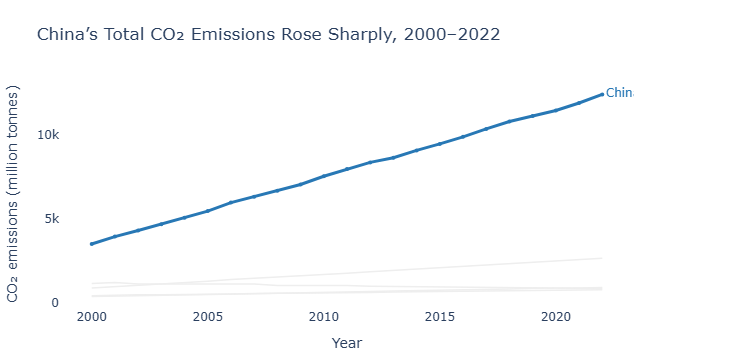

In [7]:
highlight_country = 'China'
fig = go.Figure()

for country in asia_df['Country'].unique():
    country_df = (
        asia_df[asia_df['Country'] == country]
        .sort_values('Year')
    )

    fig.add_trace(go.Scatter(
        x=country_df['Year'],
        y=country_df['CO2_Mt'],
        mode='lines',
        line=dict(color='#EEEEEE', width=1.5),
        hovertemplate=(
            f'{country}<br>Year: %{{x}}'
            '<br>CO2 emissions: %{y:,.1f} Mt<extra></extra>'
        ),
        showlegend=False
    ))

china_df = (
    asia_df[asia_df['Country'] == highlight_country]
    .sort_values('Year')
)

labels = [''] * len(china_df)
labels[-1] = 'China'

fig.add_trace(go.Scatter(
    x=china_df['Year'],
    y=china_df['CO2_Mt'],
    mode='lines+markers+text',
    line=dict(color='#2878B5', width=3),
    marker=dict(size=4),
    text=labels,
    textposition='middle right',
    textfont=dict(color='#2878B5', size=12),
    showlegend=False
))

fig.update_layout(
    title='China’s Total CO₂ Emissions Rose Sharply, 2000–2022',
    xaxis_title='Year',
    yaxis_title='CO₂ emissions (million tonnes)',
    template='plotly_white',
    showlegend=False,
    margin=dict(l=60, r=100, t=80, b=50)
)

fig.update_xaxes(showgrid=False, showline=False, zeroline=False)
fig.update_yaxes(showgrid=False, showline=False, zeroline=False)

fig.show()

